In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.datasets import make_classification

# Set Random Seed For Reproductibility
np.random.seed(42)

In [2]:
# Generate A Sample Dataset For Classfication
x, y = make_classification(n_samples=1000, n_features=20, n_classes=2, random_state=42)

# Split The Data Into Training Testing Sets
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Scale The Features 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

print(f"Dataset Shape : {x.shape}")
print(f"Number Of Classes : {len(np.unique(y))}")

Dataset Shape : (1000, 20)
Number Of Classes : 2


Logistic Regression Results : 
Accuracy : 0.86
Classification Report : 

              precision    recall  f1-score   support

           0       0.80      0.94      0.86        93
           1       0.93      0.79      0.86       107

    accuracy                           0.86       200
   macro avg       0.87      0.86      0.86       200
weighted avg       0.87      0.86      0.86       200



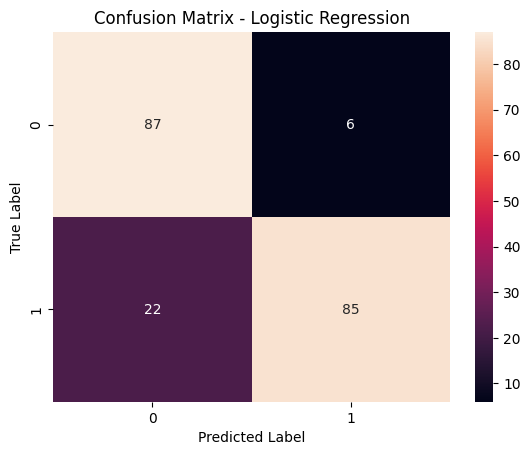

In [3]:
# Logistic Regression

from sklearn.linear_model import LogisticRegression

# Create And Train The Logistic Regression Model
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)

# Make Predictions
y_pred_lr = lr_model.predict(X_test_scaled)

# Evaluate The Model
print("Logistic Regression Results : ")
print(f"Accuracy : {accuracy_score(y_test, y_pred_lr)}")
print("Classification Report : \n")
print(classification_report(y_test, y_pred_lr))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix - Logistic Regression")
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

Naive Bayes Results : 
Accuracy :  0.7950
Classification Report : 

              precision    recall  f1-score   support

           0       0.72      0.90      0.80        93
           1       0.89      0.70      0.79       107

    accuracy                           0.80       200
   macro avg       0.81      0.80      0.79       200
weighted avg       0.81      0.80      0.79       200



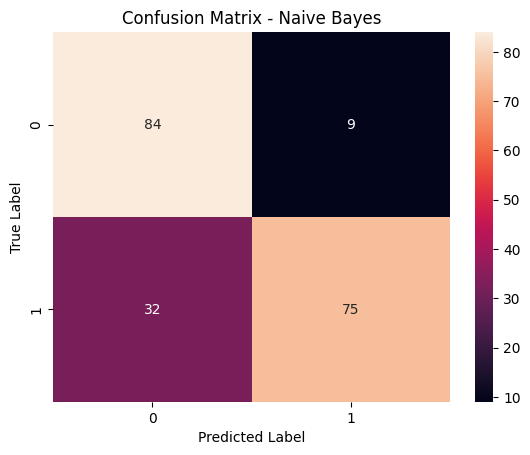

In [4]:
# Naive Bayes Classification 
from sklearn.naive_bayes import GaussianNB

# Create And Train The Naive Bayes Model
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

# Make Predictions
y_pred_nb = nb_model.predict(X_test_scaled)

# Evaluate The Model
print("Naive Bayes Results : ")
print(f"Accuracy : {accuracy_score(y_test, y_pred_nb): .4f}")
print("Classification Report : \n")
print(classification_report(y_test, y_pred_nb))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred_nb)
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix - Naive Bayes")
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

Decision Tree Results : 
Accuracy :  0.8650
Classification Report : 

              precision    recall  f1-score   support

           0       0.84      0.87      0.86        93
           1       0.88      0.86      0.87       107

    accuracy                           0.86       200
   macro avg       0.86      0.87      0.86       200
weighted avg       0.87      0.86      0.87       200



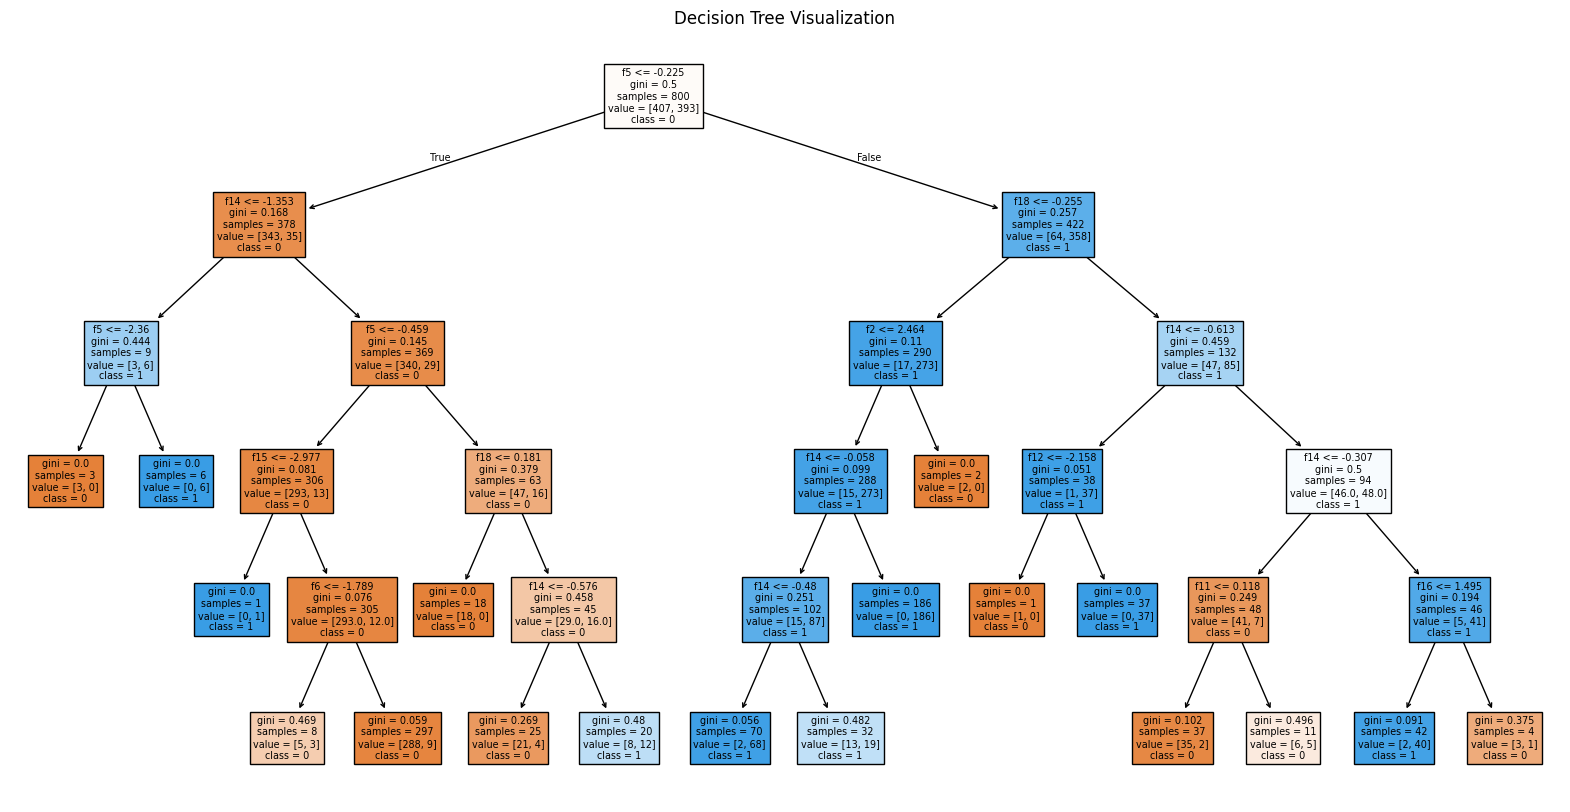

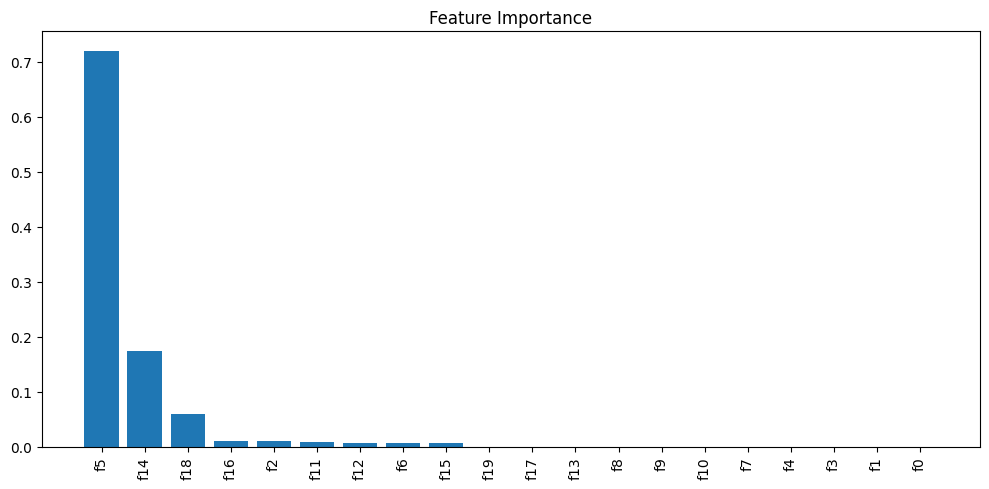

In [5]:
# Decision Trees
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Create And Train The Decision Tree Model
dt_model = DecisionTreeClassifier(random_state=42, max_depth=5)
dt_model.fit(X_train_scaled, y_train)

# Make Predictions
y_pred_dt = dt_model.predict(X_test_scaled)

# Evaluate The Model
print("Decision Tree Results : ")
print(f"Accuracy : {accuracy_score(y_test, y_pred_dt): .4f}")
print("Classification Report : \n")
print(classification_report(y_test, y_pred_dt))

# Plot The Decision Tree
plt.figure(figsize=(20, 10))
plot_tree(dt_model, filled=True, feature_names=[f'f{i}' for i in range(20)], class_names=['0', '1'])
plt.title("Decision Tree Visualization")
plt.show()

# Plot Features Importance
importances = dt_model.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(10, 5))
plt.title("Feature Importance")
plt.bar(range(20), importances[indices])
plt.xticks(range(20), [f'f{i}' for i in indices], rotation=90)
plt.tight_layout()
plt.show()

Dataset Shape : (1000, 20)
Number Of Classes : 2
SVm Results : 
Accuracy :  0.8950
Classification Report : 

              precision    recall  f1-score   support

           0       0.86      0.94      0.90       101
           1       0.93      0.85      0.89        99

    accuracy                           0.90       200
   macro avg       0.90      0.89      0.89       200
weighted avg       0.90      0.90      0.89       200



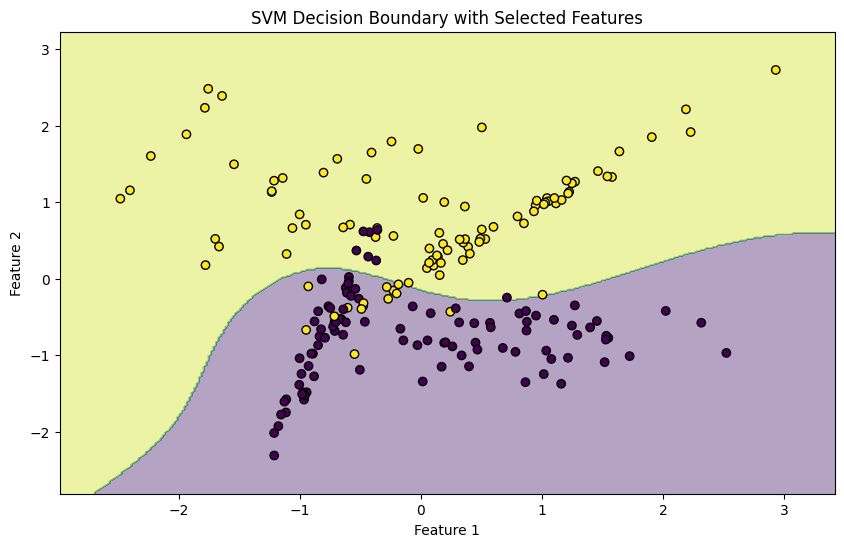

In [6]:
# SVC
from sklearn.svm import SVC

# Generate A Sample Dataset For Classfication
x_svm, y_svm = make_classification(n_samples=1000, n_features=2, n_informative=2,n_redundant=0,random_state=42)

# Split The Data Into Training Testing Sets
X_train_svm, X_test_svm, y_train_svm, y_test_svm = train_test_split(x_svm, y_svm, test_size=0.2, random_state=42)

# Scale The Features 
scaler_svm = StandardScaler()
X_train_scaled_svm = scaler.fit_transform(X_train_svm)
X_test_scaled_svm = scaler.fit_transform(X_test_svm)

print(f"Dataset Shape : {x.shape}")
print(f"Number Of Classes : {len(np.unique(y_svm))}")

# Create And Train The Naive Bayes Model
svm_model = SVC(kernel='rbf', random_state=42)
svm_model.fit(X_train_scaled_svm, y_train_svm)

# Make Predictions
y_pred_svm = svm_model.predict(X_test_scaled_svm)

# Evaluate The Model
print("SVm Results : ")
print(f"Accuracy : {accuracy_score(y_test_svm, y_pred_svm): .4f}")
print("Classification Report : \n")
print(classification_report(y_test_svm, y_pred_svm))

# Plot Decision Boundary (For 2D Visualization)
def plot_decision_boundary(model, x, y):
    x_min, x_max = x[:, 0].min() - 0.5, x[ :, 0].max() + 0.5
    y_min, y_max = x[:, 1].min() - 0.5, x[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    z = model.predict(scaler.transform(np.c_[xx.ravel(), yy.ravel()])) # Ensure input data is scaled
    z = z.reshape(xx.shape)
    plt.contourf(xx, yy, z, alpha=0.4)
    plt.scatter (x[ :, 0], x[ :, 1], c=y, edgecolor='k' , marker='o')
    plt.title('SVM Decision Boundary with Selected Features')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.show()
    
plt.figure(figsize=(10, 6))
plot_decision_boundary(svm_model, X_test_scaled_svm, y_test_svm)
plt. show()

Random Forest Results : 
Accuracy :  0.8850
Classification Report : 

              precision    recall  f1-score   support

           0       0.86      0.90      0.88        93
           1       0.91      0.87      0.89       107

    accuracy                           0.89       200
   macro avg       0.88      0.89      0.88       200
weighted avg       0.89      0.89      0.89       200



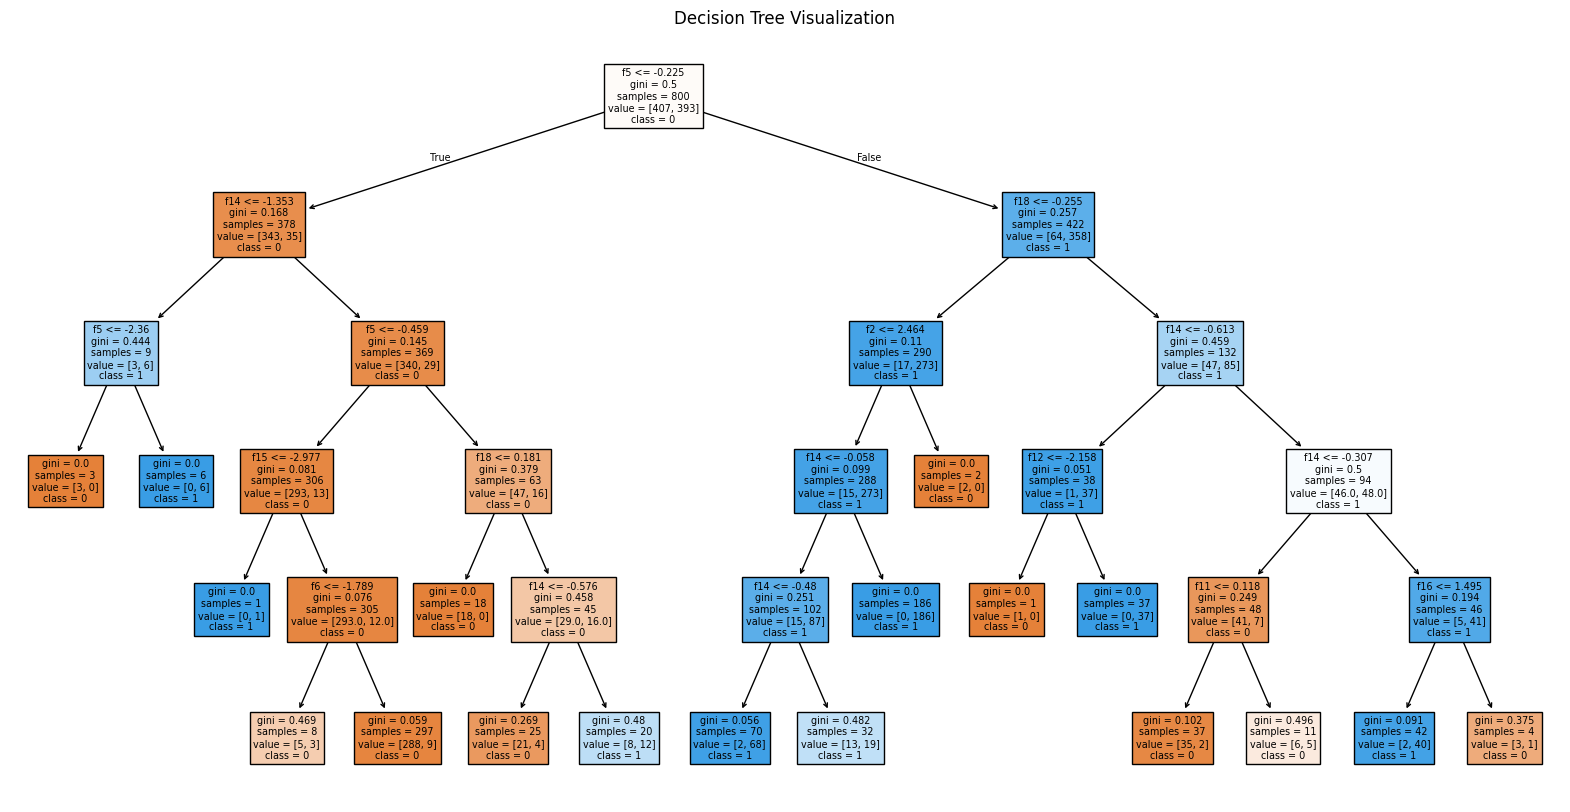

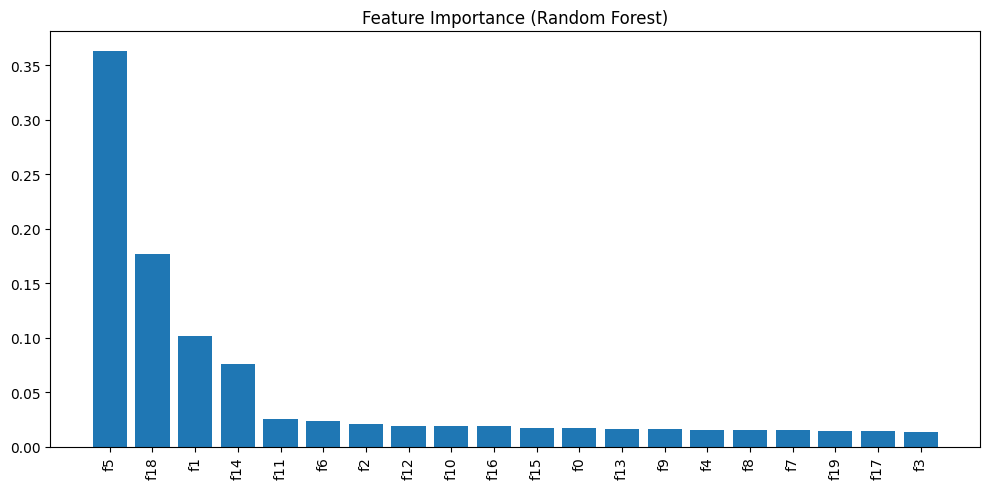

In [7]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

# Create And Train The Decision Tree Model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

# Make Predictions
y_pred_rf = rf_model.predict(X_test_scaled)

# Evaluate The Model
print("Random Forest Results : ")
print(f"Accuracy : {accuracy_score(y_test, y_pred_rf): .4f}")
print("Classification Report : \n")
print(classification_report(y_test, y_pred_rf))

# Plot The Decision Tree
plt.figure(figsize=(20, 10))
plot_tree(dt_model, filled=True, feature_names=[f'f{i}' for i in range(20)], class_names=['0', '1'])
plt.title("Decision Tree Visualization")
plt.show()

# Plot Features Importance
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]
plt.figure(figsize=(10, 5))
plt.title("Feature Importance (Random Forest)")
plt.bar(range(20), importances[indices])
plt.xticks(range(20), [f'f{i}' for i in indices], rotation=90)
plt.tight_layout()
plt.show()

Gradient Boosting Results:
Accuracy: 0.8800
Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.91      0.88        93
           1       0.92      0.85      0.88       107

    accuracy                           0.88       200
   macro avg       0.88      0.88      0.88       200
weighted avg       0.88      0.88      0.88       200



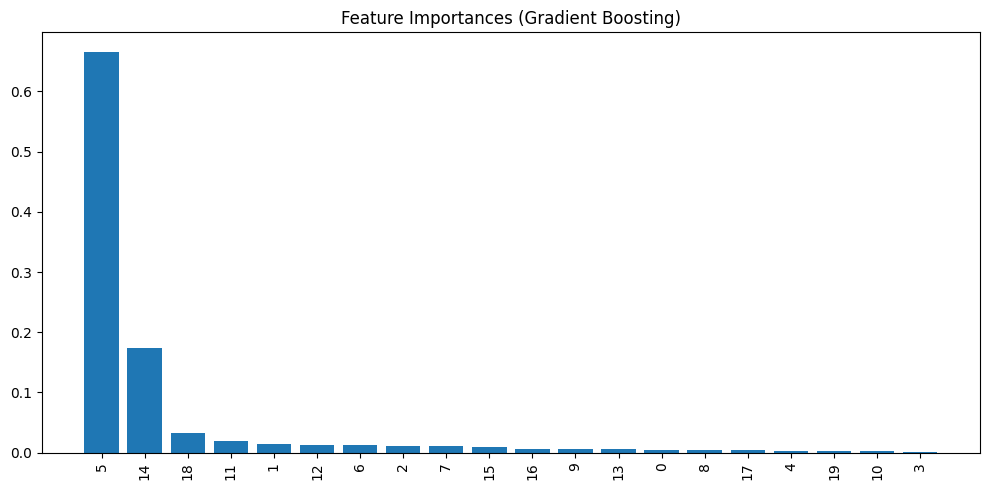

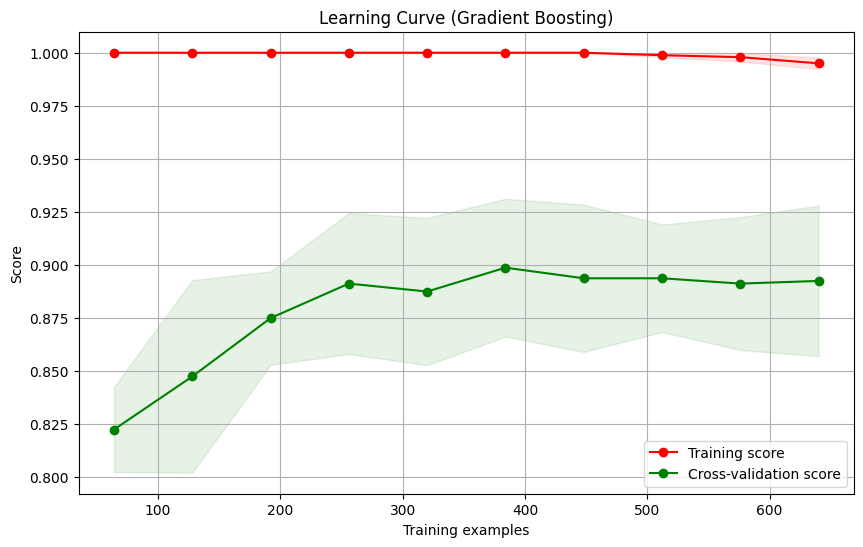

In [8]:
# Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import numpy as np

# Create and train the Gradient Boosting model
gb_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
gb_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_gb = gb_model.predict(X_test_scaled)

# Evaluate the model
print("Gradient Boosting Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_gb):.4f}")
print("Classification Report:")
print(classification_report(y_test, y_pred_gb))

# Plot feature importance
importances = gb_model.feature_importances_
indices = np.argsort(importances)[::-1]   # ← تصحيح المسافة

plt.figure(figsize=(10,5))
plt.title("Feature Importances (Gradient Boosting)")
plt.bar(range(20), importances[indices[:20]])  # ← لازم نجيب أول 20 feature بس
plt.xticks(range(20), [f'{i}' for i in indices[:20]], rotation=90)
plt.tight_layout()   # ← تصحيح المسافات
plt.show()           # ← تصحيح المسافات

# Plot learning curve
from sklearn.model_selection import learning_curve

train_sizes, train_scores, test_scores = learning_curve(
    gb_model, X_train_scaled, y_train, cv=5, n_jobs=-1,   # ← تصحيح n_jobs
    train_sizes=np.linspace(0.1, 1.0, 10), scoring="accuracy"
)

train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)
test_scores_std = np.std(test_scores, axis=1)

plt.figure(figsize=(10, 6))
plt.title("Learning Curve (Gradient Boosting)")
plt.xlabel("Training examples")
plt.ylabel("Score")
plt.grid()

plt.fill_between(train_sizes,
                 train_scores_mean - train_scores_std,
                 train_scores_mean + train_scores_std, alpha=0.1, color="r")
plt.fill_between(train_sizes,
                 test_scores_mean - test_scores_std,
                 test_scores_mean + test_scores_std, alpha=0.1, color="g")

plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Training score")
plt.plot(train_sizes, test_scores_mean, 'o-', color="g", label="Cross-validation score")

plt.legend(loc="best")
plt.show()


Bagging Classifier Results:
Accuracy: 0.8700

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.90      0.87        93
           1       0.91      0.84      0.87       107

    accuracy                           0.87       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.87      0.87      0.87       200


AdaBoost Classifier Results:
Accuracy: 0.8700

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.88      0.86        93
           1       0.89      0.86      0.88       107

    accuracy                           0.87       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.87      0.87      0.87       200



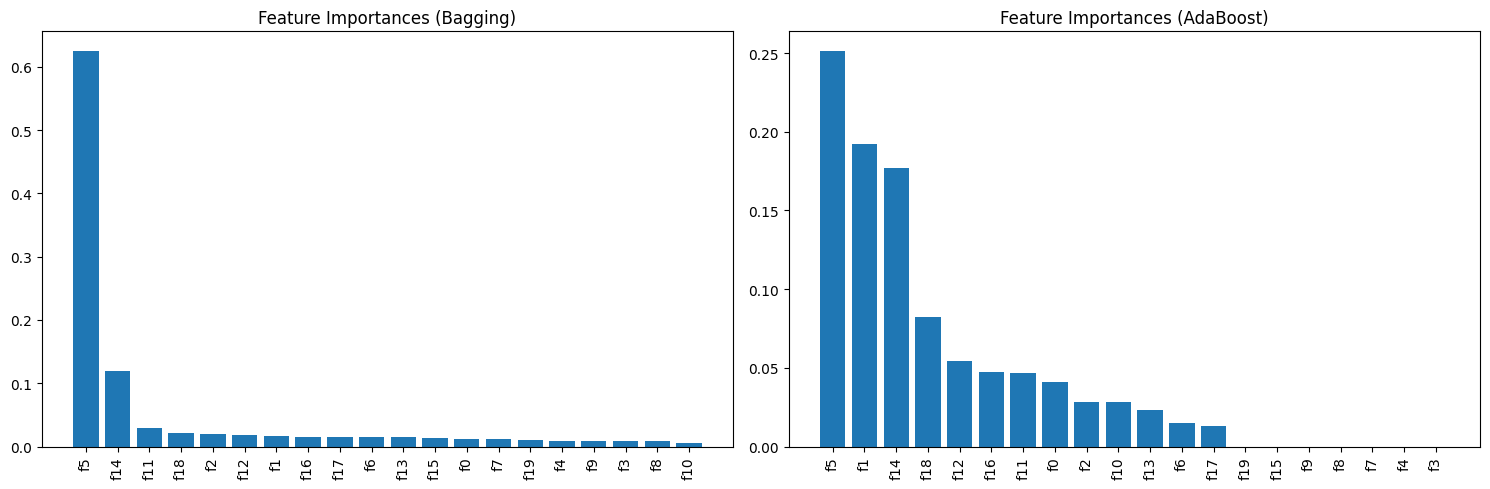

In [ ]:
# Bagging & Boosting

from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import numpy as np

# Bagging Classifier
bagging_model = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=10, random_state=42)
bagging_model.fit(X_train_scaled, y_train)
y_pred_bagging = bagging_model.predict(X_test_scaled)

# AdaBoost Classifier
adaboost_model = AdaBoostClassifier(n_estimators=50, random_state=42)
adaboost_model.fit(X_train_scaled, y_train)
y_pred_adaboost = adaboost_model.predict(X_test_scaled)

# Evaluate models
print("Bagging Classifier Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_bagging):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_bagging))

print("\nAdaBoost Classifier Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_adaboost):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_adaboost))

# Compare feature importances
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Bagging feature importance (average over all trees)
importances_bagging = np.mean([tree.feature_importances_ for tree in bagging_model.estimators_], axis=0)
indices_bagging = np.argsort(importances_bagging)[::-1]
ax1.bar(range(20), importances_bagging[indices_bagging][:20])
ax1.set_title("Feature Importances (Bagging)")
ax1.set_xticks(range(20))
ax1.set_xticklabels([f'f{i}' for i in indices_bagging[:20]], rotation=90)

# AdaBoost feature importance
importances_adaboost = adaboost_model.feature_importances_
indices_adaboost = np.argsort(importances_adaboost)[::-1]
ax2.bar(range(20), importances_adaboost[indices_adaboost][:20])
ax2.set_title("Feature Importances (AdaBoost)")
ax2.set_xticks(range(20))
ax2.set_xticklabels([f'f{i}' for i in indices_adaboost[:20]], rotation=90)

plt.tight_layout() 
plt.show()
